# 03 — Classical Machine Learning Baselines

## Research objective

This notebook establishes the first supervised machine-learning baselines for TopicSense-NLP.

The experiments compare three classical classifiers:

- Multinomial Naive Bayes.
- Logistic Regression.
- Linear Support Vector Machine.

Two feature representations are evaluated:

- Bag of Words using raw term counts.
- TF-IDF using term-frequency and inverse-document-frequency weighting.

Each model is evaluated using both complete messages and extracted message bodies.

This creates a controlled comparison of 12 configurations.

## Experimental protocol

The experiments use the official training and validation partitions generated in Notebook 02.

The following rules apply:

1. Training records are used to fit vectorizers and classifiers.
2. Validation records are used to compare configurations.
3. The official test partition is not used in this notebook.
4. The same split and random seed are used across configurations.
5. Macro-F1 is the primary model-selection metric.
6. Accuracy, macro precision, macro recall and weighted F1 provide complementary evidence.
7. Training duration, inference time, throughput and serialized artifact size are recorded.

The experiments use reusable implementations in `src/topicsense/`. This notebook orchestrates the experiments and analyses their observed results.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import yaml

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise FileNotFoundError(
        "Could not locate the project root containing pyproject.toml."
    )

SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

import topicsense.training.classical  # noqa: E402

run_classical_experiments = (
    topicsense.training.classical.run_classical_experiments
)

CONFIG_PATH = PROJECT_ROOT / "configs" / "classical_ml.yaml"

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    CONFIG = yaml.safe_load(file)

RANDOM_SEED = CONFIG["project"]["random_seed"]

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", context="notebook")

print(f"Project root: {PROJECT_ROOT}")
print(f"Random seed: {RANDOM_SEED}")
print(f"Configuration: {CONFIG_PATH}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Random seed: 42
Configuration: /home/nkululekocyrilcele/projects/topicsense-nlp/configs/classical_ml.yaml


## 1. Verify experiment inputs

Before training, verify that the raw dataset, official training/validation split manifest and configuration are available.

The experiment runner filters the dataset to official training records and selects records using the split manifest. It does not use the official test partition.

The vectorizers are included in scikit-learn pipelines. This ensures that vocabulary construction and feature weighting are fitted as part of the training operation rather than using validation data.

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / CONFIG["data"]["raw_dataset_path"]
SPLIT_PATH = PROJECT_ROOT / CONFIG["data"]["split_manifest_path"]

assert RAW_DATA_PATH.is_file(), RAW_DATA_PATH
assert SPLIT_PATH.is_file(), SPLIT_PATH
assert CONFIG_PATH.is_file(), CONFIG_PATH

print("Experiment inputs verified.")
print(f"Raw dataset: {RAW_DATA_PATH}")
print(f"Development split: {SPLIT_PATH}")

print("\nConfigured classifiers:")
for name, settings in CONFIG["classifiers"].items():
    print(f"- {name}: enabled={settings['enabled']}")

print("\nFeature representations:")
for feature_type in CONFIG["features"]["types"]:
    print(f"- {feature_type}")

print("\nText representations:")
for representation in CONFIG["preprocessing"]["representations"]:
    print(f"- {representation}")

Experiment inputs verified.
Raw dataset: /home/nkululekocyrilcele/projects/topicsense-nlp/data/raw/20newsgroups/20newsgroups_raw.jsonl
Development split: /home/nkululekocyrilcele/projects/topicsense-nlp/data/interim/20newsgroups/splits/official_training_split.json

Configured classifiers:
- multinomial_nb: enabled=True
- logistic_regression: enabled=True
- linear_svm: enabled=True

Feature representations:
- count
- tfidf

Text representations:
- full_message
- message_body


## 2. Execute the classical baseline experiments

The experiment runner evaluates the configured combinations of classifiers, vectorizers and text representations.

Each configuration is trained independently using the same development split.

The resulting metrics are based on validation predictions. No test performance is calculated at this stage.

In [3]:
EXPERIMENT_RESULTS = run_classical_experiments(
    CONFIG,
    project_root=PROJECT_ROOT,
)

results_df = pd.DataFrame(EXPERIMENT_RESULTS["summary"])

print(f"Completed configurations: {len(results_df)}")

display(
    results_df.sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    ).reset_index(drop=True)
)

multinomial_nb__count__full_message: macro-F1=0.8272, accuracy=0.8383, fit=11.25s
logistic_regression__count__full_message: macro-F1=0.8731, accuracy=0.8732, fit=106.00s


/home/nkululekocyrilcele/projects/topicsense-nlp/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


linear_svm__count__full_message: macro-F1=0.8793, accuracy=0.8785, fit=64.74s
multinomial_nb__tfidf__full_message: macro-F1=0.8293, accuracy=0.8409, fit=15.81s
logistic_regression__tfidf__full_message: macro-F1=0.8795, accuracy=0.8811, fit=61.59s
linear_svm__tfidf__full_message: macro-F1=0.9138, accuracy=0.9147, fit=17.02s
multinomial_nb__count__message_body: macro-F1=0.8046, accuracy=0.8193, fit=10.61s
logistic_regression__count__message_body: macro-F1=0.8219, accuracy=0.8219, fit=191.80s


/home/nkululekocyrilcele/projects/topicsense-nlp/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


linear_svm__count__message_body: macro-F1=0.8046, accuracy=0.8060, fit=55.06s
multinomial_nb__tfidf__message_body: macro-F1=0.8053, accuracy=0.8184, fit=8.98s
logistic_regression__tfidf__message_body: macro-F1=0.8550, accuracy=0.8604, fit=40.58s
linear_svm__tfidf__message_body: macro-F1=0.8947, accuracy=0.8966, fit=13.50s
Completed configurations: 12


,run_id,experiment_id,classifier,feature_type,representation,training_documents,validation_documents,feature_count,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds,prediction_seconds,latency_ms_per_document,throughput_documents_per_second,artifact_size_bytes
0,linear_svm__tfidf__full_message,EXP-03,linear_svm,tfidf,full_message,9051,2263,100000,0.914715,0.916963,0.912511,0.913779,0.914656,17.023387,1.149334,0.507881,1968.965596,19902488
1,linear_svm__tfidf__message_body,EXP-03,linear_svm,tfidf,message_body,9051,2263,100000,0.896597,0.899874,0.892915,0.894659,0.896266,13.499522,0.876050,0.387119,2583.187221,19900296
2,logistic_regression__tfidf__full_message,EXP-02,logistic_regression,tfidf,full_message,9051,2263,100000,0.881131,0.888241,0.876884,0.879464,0.881175,61.593530,1.131924,0.500187,1999.251112,19902636
3,linear_svm__count__full_message,EXP-03,linear_svm,count,full_message,9051,2263,100000,0.878480,0.882670,0.877399,0.879308,0.878930,64.738583,5.171664,2.285313,437.576771,19102389
4,logistic_regression__count__full_message,EXP-02,logistic_regression,count,full_message,9051,2263,100000,0.873177,0.877364,0.871022,0.873074,0.873539,106.001063,1.119928,0.494886,2020.666432,19102536
5,logistic_regression__tfidf__message_body,EXP-02,logistic_regression,tfidf,message_body,9051,2263,100000,0.860362,0.872132,0.852760,0.854986,0.859162,40.576838,1.116713,0.493466,2026.482245,19900444
6,multinomial_nb__tfidf__full_message,EXP-01,multinomial_nb,tfidf,full_message,9051,2263,100000,0.840919,0.865745,0.828533,0.829320,0.837485,15.807542,0.987591,0.436408,2291.434417,35902689
7,multinomial_nb__count__full_message,EXP-01,multinomial_nb,count,full_message,9051,2263,100000,0.838268,0.855845,0.837584,0.827190,0.826129,11.250238,1.205769,0.532819,1876.810400,35102605
8,logistic_regression__count__message_body,EXP-02,logistic_regression,count,message_body,9051,2263,100000,0.821918,0.829420,0.818797,0.821850,0.822896,191.799504,1.122451,0.496001,2016.123628,19100344
9,multinomial_nb__tfidf__message_body,EXP-01,multinomial_nb,tfidf,message_body,9051,2263,100000,0.818383,0.854553,0.803533,0.805293,0.815361,8.984214,1.177266,0.520224,1922.249924,35900497


## 3. Compare aggregate classification performance

Macro-F1 is the primary comparison metric because it assigns equal importance to each class.

Accuracy measures the proportion of correct predictions across all validation documents. Weighted F1 accounts for class support, while macro precision and recall provide further information about class-level behaviour.

The ranking below is based on validation macro-F1. It identifies promising configurations for subsequent analysis; it does not constitute a final test-set ranking.

In [4]:
performance_columns = [
    "classifier",
    "feature_type",
    "representation",
    "accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
]

performance_table = (
    results_df[performance_columns]
    .sort_values(
        ["macro_f1", "accuracy"],
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    performance_table.style.format(
        {
            "accuracy": "{:.4f}",
            "macro_precision": "{:.4f}",
            "macro_recall": "{:.4f}",
            "macro_f1": "{:.4f}",
            "weighted_f1": "{:.4f}",
        }
    )
)

best_run_summary = performance_table.iloc[0]

print("Best validation configuration by macro-F1:")
display(best_run_summary.to_frame(name="value"))

,classifier,feature_type,representation,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,linear_svm,tfidf,full_message,0.9147,0.9170,0.9125,0.9138,0.9147
1,linear_svm,tfidf,message_body,0.8966,0.8999,0.8929,0.8947,0.8963
2,logistic_regression,tfidf,full_message,0.8811,0.8882,0.8769,0.8795,0.8812
3,linear_svm,count,full_message,0.8785,0.8827,0.8774,0.8793,0.8789
4,logistic_regression,count,full_message,0.8732,0.8774,0.8710,0.8731,0.8735
5,logistic_regression,tfidf,message_body,0.8604,0.8721,0.8528,0.8550,0.8592
6,multinomial_nb,tfidf,full_message,0.8409,0.8657,0.8285,0.8293,0.8375
7,multinomial_nb,count,full_message,0.8383,0.8558,0.8376,0.8272,0.8261
8,logistic_regression,count,message_body,0.8219,0.8294,0.8188,0.8219,0.8229
9,multinomial_nb,tfidf,message_body,0.8184,0.8546,0.8035,0.8053,0.8154


Best validation configuration by macro-F1:


,value
classifier,linear_svm
feature_type,tfidf
representation,full_message
accuracy,0.914715
macro_precision,0.916963
macro_recall,0.912511
macro_f1,0.913779
weighted_f1,0.914656


## 4. Analyse the best validation configuration

Aggregate metrics can conceal differences between individual classes.

The following analysis examines the precision, recall and F1-score of each class for the configuration with the highest validation macro-F1.

This is useful for identifying categories that remain difficult to distinguish, even when overall performance is strong.

In [5]:
best_run_id = str(best_run_summary["classifier"]) + "__" + str(
    best_run_summary["feature_type"]
) + "__" + str(best_run_summary["representation"])

best_run = next(
    run
    for run in EXPERIMENT_RESULTS["runs"]
    if run["run_id"] == best_run_id
)

best_per_class = pd.DataFrame.from_dict(
    best_run["metrics"]["per_class"],
    orient="index",
)

best_per_class.index.name = "class"

display(
    best_per_class.sort_values(
        "f1_score",
        ascending=True,
    ).style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
        }
    )
)

,precision,recall,f1_score,support
class,,,,
comp.sys.ibm.pc.hardware,0.7863,0.7797,0.7830,118
comp.graphics,0.7846,0.8793,0.8293,116
talk.religion.misc,0.9344,0.7500,0.8321,76
misc.forsale,0.8443,0.8803,0.8619,117
comp.windows.x,0.8678,0.8824,0.8750,119
comp.os.ms-windows.misc,0.8618,0.8983,0.8797,118
sci.electronics,0.9259,0.8403,0.8811,119
comp.sys.mac.hardware,0.8879,0.8957,0.8918,115
rec.autos,0.9474,0.9076,0.9270,119


## 5. Inspect the confusion matrix

The confusion matrix shows how the best validation configuration distributes its predictions across the 20 classes.

Rows represent actual classes and columns represent predicted classes.

Off-diagonal values indicate classification errors. They can help identify categories with overlapping vocabulary or ambiguous discussion content.

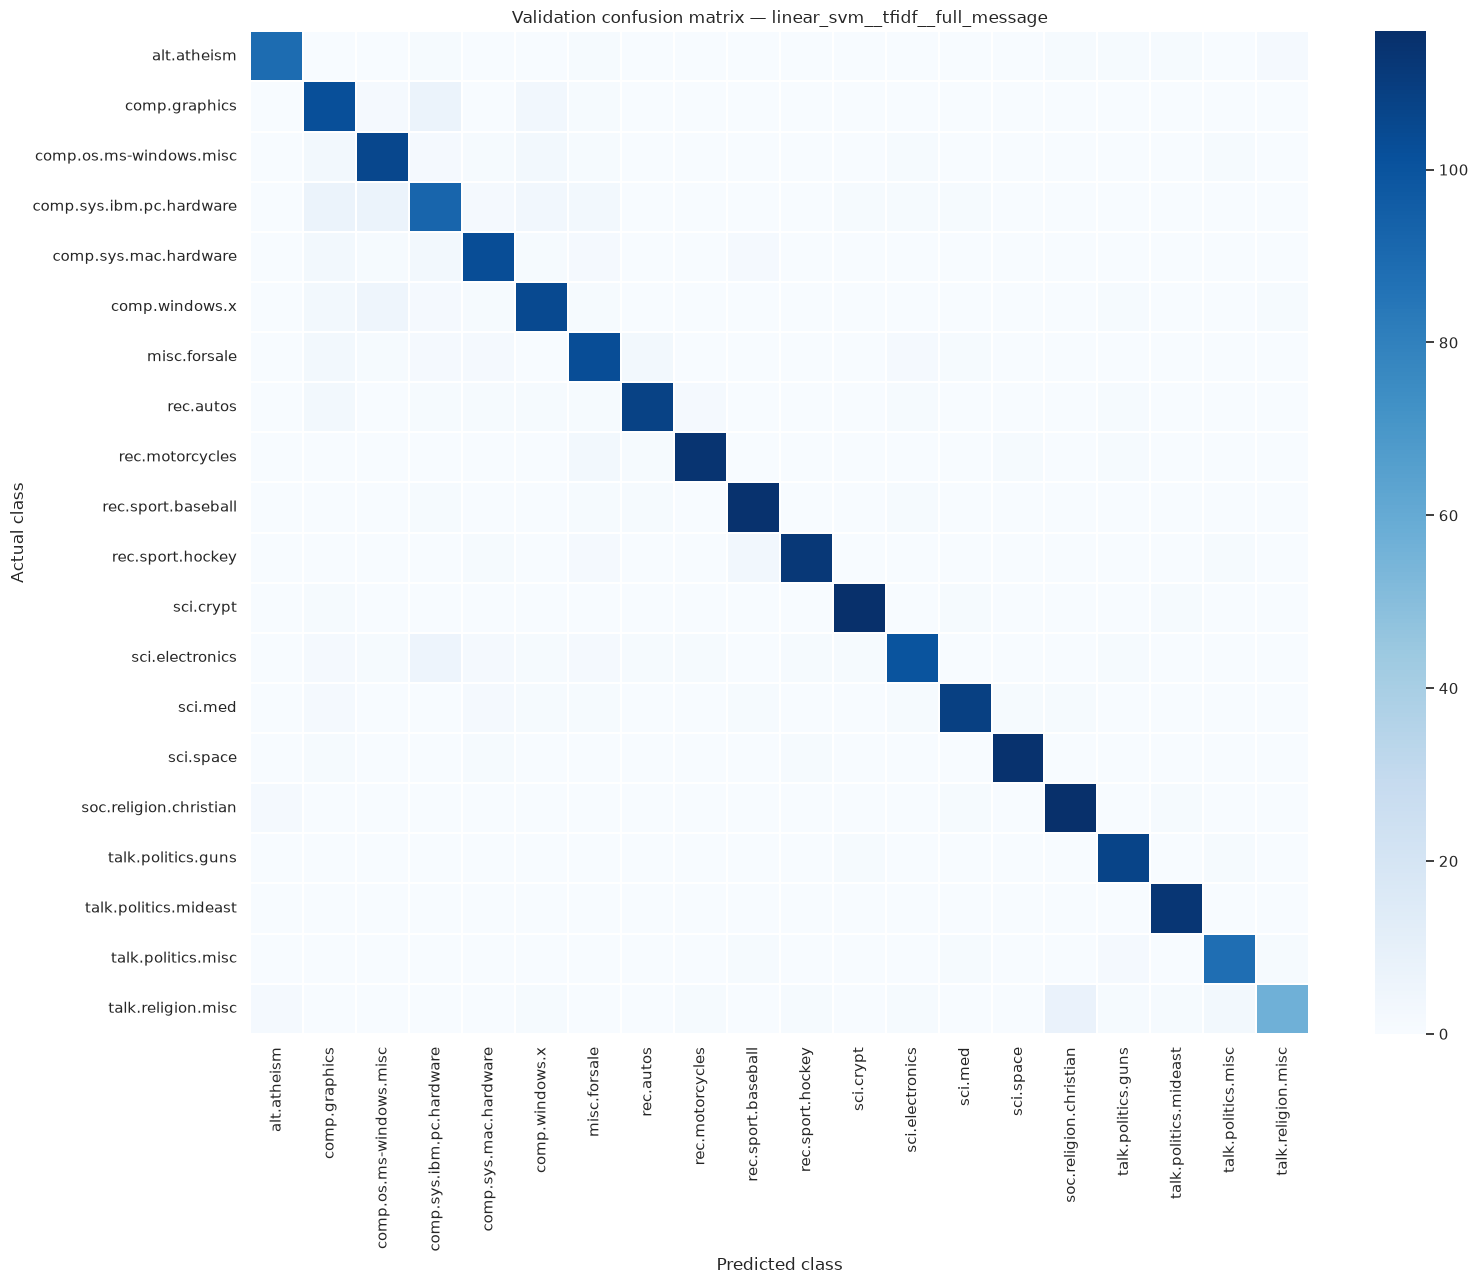

In [6]:
class_labels = best_run["metrics"]["class_labels"]

confusion_df = pd.DataFrame(
    best_run["metrics"]["confusion_matrix"],
    index=class_labels,
    columns=class_labels,
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    confusion_df,
    cmap="Blues",
    annot=False,
    fmt="d",
    linewidths=0.1,
)

plt.title(f"Validation confusion matrix — {best_run_id}")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Compare feature and text representations

The experiment matrix allows us to examine whether the relative performance of the classifiers changes when the feature representation or source text changes.

The comparison is descriptive. It should not be interpreted as evidence that one feature representation is universally superior.

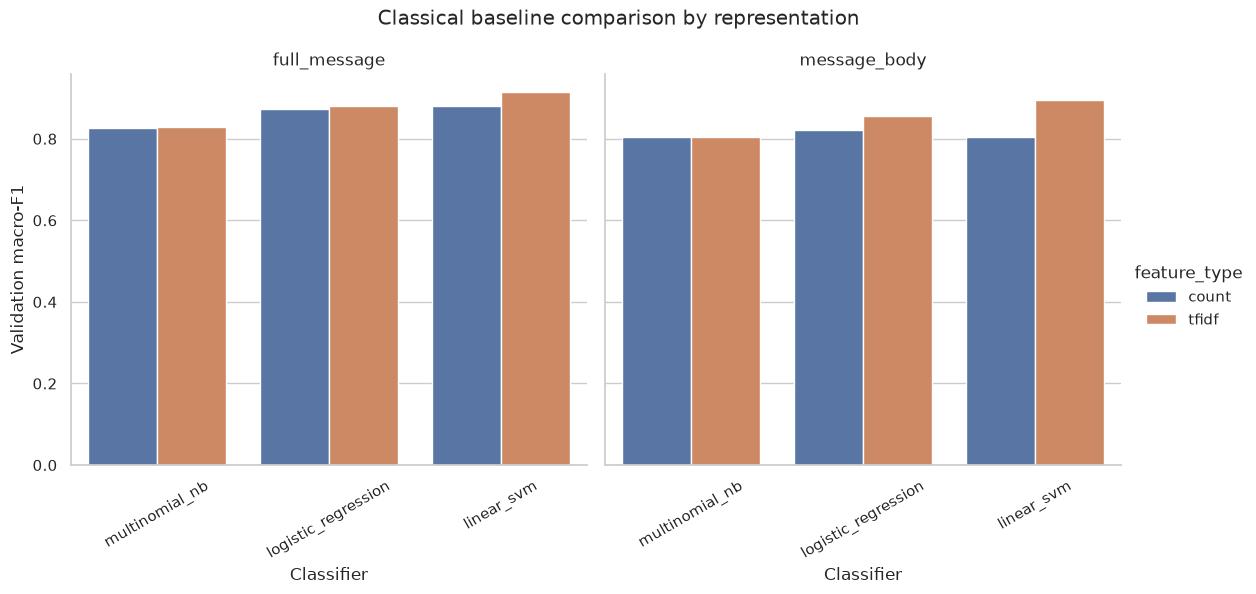

Saved comparison figure: /home/nkululekocyrilcele/projects/topicsense-nlp/results/figures/classical_baseline_comparison.png


In [7]:
comparison_plot = sns.catplot(
    data=results_df,
    x="classifier",
    y="macro_f1",
    hue="feature_type",
    col="representation",
    kind="bar",
    height=5,
    aspect=1.15,
    sharey=True,
)

comparison_plot.set_axis_labels(
    "Classifier",
    "Validation macro-F1",
)

comparison_plot.set_titles("{col_name}")

comparison_plot.set_xticklabels(rotation=30)

comparison_plot.figure.suptitle(
    "Classical baseline comparison by representation",
    y=1.05,
)

plt.show()

figure_path = (
    PROJECT_ROOT
    / "results"
    / "figures"
    / "classical_baseline_comparison.png"
)

figure_path.parent.mkdir(parents=True, exist_ok=True)

comparison_plot.figure.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
)

print(f"Saved comparison figure: {figure_path}")

## 7. Computational efficiency

Predictive performance is only one part of the comparison.

The experiments also record:

- Model fitting time.
- Validation prediction time.
- Average prediction latency per document.
- Prediction throughput.
- Serialized model artifact size.

These measurements were collected in the same execution environment, but should still be interpreted in context. They are measurements of these particular runs, not universal estimates of model performance on all hardware.

In [8]:
efficiency_columns = [
    "classifier",
    "feature_type",
    "representation",
    "fit_seconds",
    "prediction_seconds",
    "latency_ms_per_document",
    "throughput_documents_per_second",
    "artifact_size_bytes",
]

efficiency_table = results_df[efficiency_columns].sort_values(
    ["fit_seconds", "prediction_seconds"],
    ascending=True,
)

display(
    efficiency_table.style.format(
        {
            "fit_seconds": "{:.3f}",
            "prediction_seconds": "{:.4f}",
            "latency_ms_per_document": "{:.4f}",
            "throughput_documents_per_second": "{:.2f}",
            "artifact_size_bytes": "{:,.0f}",
        }
    )
)

,classifier,feature_type,representation,fit_seconds,prediction_seconds,latency_ms_per_document,throughput_documents_per_second,artifact_size_bytes
9,multinomial_nb,tfidf,message_body,8.984,1.1773,0.5202,1922.25,"35,900,497"
6,multinomial_nb,count,message_body,10.611,1.0387,0.4590,2178.62,"35,100,413"
0,multinomial_nb,count,full_message,11.250,1.2058,0.5328,1876.81,"35,102,605"
11,linear_svm,tfidf,message_body,13.500,0.8760,0.3871,2583.19,"19,900,296"
3,multinomial_nb,tfidf,full_message,15.808,0.9876,0.4364,2291.43,"35,902,689"
5,linear_svm,tfidf,full_message,17.023,1.1493,0.5079,1968.97,"19,902,488"
10,logistic_regression,tfidf,message_body,40.577,1.1167,0.4935,2026.48,"19,900,444"
8,linear_svm,count,message_body,55.059,1.0753,0.4752,2104.47,"19,100,197"
4,logistic_regression,tfidf,full_message,61.594,1.1319,0.5002,1999.25,"19,902,636"
2,linear_svm,count,full_message,64.739,5.1717,2.2853,437.58,"19,102,389"


## 8. Persisted experiment results

The experiment runner stores:

- Aggregate metrics in `results/metrics/classical_baselines.csv`.
- Detailed experiment records, class-level metrics and confusion matrices in `results/logs/classical_baselines.json`.
- The comparison figure in `results/figures/`.

These outputs provide the evidence for the subsequent model comparison and error-analysis stages.

The models are not automatically registered in MLflow at this stage. MLflow integration will be introduced in its dedicated engineering phase.

In [9]:
print("Experiment output files")

for output_path in [
    EXPERIMENT_RESULTS["metrics_csv"],
    EXPERIMENT_RESULTS["results_json"],
    str(figure_path.relative_to(PROJECT_ROOT)),
]:
    path = PROJECT_ROOT / output_path
    print(f"{path}: {'FOUND' if path.is_file() else 'MISSING'}")

assert len(results_df) == 12
assert results_df["macro_f1"].between(0.0, 1.0).all()
assert results_df["accuracy"].between(0.0, 1.0).all()

print("\nBaseline output checks passed.")

Experiment output files
/home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/classical_baselines.csv: FOUND
/home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/classical_baselines.json: FOUND
/home/nkululekocyrilcele/projects/topicsense-nlp/results/figures/classical_baseline_comparison.png: FOUND

Baseline output checks passed.


## 9. Interpretation and hand-off

The experiments establish validation baselines for Multinomial Naive Bayes, Logistic Regression and Linear SVM using count-based and TF-IDF representations.

The results should be interpreted in relation to:

- Differences between the classifiers.
- The effect of count-based and TF-IDF features.
- Differences between complete messages and message bodies.
- Per-class precision, recall and F1-score.
- Training and inference efficiency.

No configuration should be declared the final project winner solely on the basis of this notebook. Further investigation will include training-size experiments, controlled preprocessing comparisons, the decontaminated-training sensitivity analysis and final evaluation on the reserved test partitions.

The official benchmark remains the primary reference. The clean-test and decontaminated-training sensitivity evaluations must be reported separately.

All conclusions in the final research report must be based on the measured results produced by the executed experiments.